# Arboles de desición y ensamble: Random Forest Regressor
**Problema:** regresión supervisada. 

El **objetivo** es estimar el volumen de compras recientes de productos de Amazon.

Objetos clave para el notebook:
- **Dataset:** dataset_v4.csv (31.202 registros esperados).
- **Objetivo de entrenamiento:** log_bought = log1p(bought_in_last_month).
- **Variable auxiliar:** bought_cat, utilizada únicamente para estratificar.
- **Semilla:** 42.
- **Modelo:** RandomForestRegressor.

## Introducción
Este notebook se usará para representar los árboles de desición que se pide para esta segunda entrega, por lo que se decidió usar Random Forest como método de ensamble.

Ya que es un método que construye múltiples árboles de decisión utilizando muestras bootstrap de los datos y subconjuntos aleatorios de características. Para regresión, combina las predicciones de los árboles, normalmente mediante su promedio.

Se utilizará para predecir `log_bought`, una transformación logarítmica del volumen de compras en el último mes. Esta transformación reduce la influencia de la fuerte asimetría de la variable objetivo.

Random Forest no requiere estandarizar las variables numéricas. Sin embargo, sí debemos codificar la variable categórica buy_box_status.

**Alcance:** Este Notebook se concentra en Random Forest Regressor.

## Librerias
Se utilizarán pandas y NumPy para manipulación de datos; Matplotlib y Seaborn para visualización; y scikit-learn para el preprocesamiento, partición, entrenamiento y evaluación.

In [2]:
# Carga y configuración de librerías
import os
import json
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split, ParameterSampler
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    mean_squared_log_error
)

import joblib

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

## Configuracón inicial
- Se fija una semilla en 0 para que la división de datos y la búsqueda de hiperparámetros puedan reproducirse. 
- Se ajusta DATA_PATH a la ubicación real del archivo dataset_v4.csv.
- Se decide la configuración de los datos, dejando un 15% para validación y otro 15% para pruebas.

In [ ]:
# Carga y validación de datos
RANDOM_STATE = 0
TEST_SIZE = 0.15
VALIDATION_SIZE = 0.15
OUTPUT_DIR = Path("Models_Results/results_random_forest") #Usar solo "results_random_forest"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Ajustar esta ruta si el archivo se encuentra en otra ubicación.
DATA_PATH = Path("Limpieza de datos/dataset_v4.csv") #Usar: "/content/drive/MyDrive/ProductScope-ML/Limpieza de datos/dataset_v4.csv"
                                                     #Si se ejecuta en Colab.

# Rutas alternativas habituales (Colab/local).
ALTERNATIVE_PATHS = [
    Path("dataset_v4.csv"),
    Path("Limpieza de datos/dataset_v4.csv"),
    Path("../Limpieza de datos/dataset_v4.csv"),
]

print("Directorio de trabajo:", Path.cwd())
print("Directorio de resultados:", OUTPUT_DIR.resolve())

Directorio de trabajo: c:\Users\Juan Mona\Documents\Repositories\ProductScope-ML\Modelos entrenados
Directorio de resultados: C:\Users\Juan Mona\Documents\Repositories\ProductScope-ML\Modelos entrenados\Models_Results\results_random_forest


## Carga de datos y validación
Se carga exclusivamente la variante v4. ya que para este caso, es el dataset con una mayor cantidad de datos necesarios para realizar al experimentación y el entrenamiento mas completo y adecuado

In [13]:
if not DATA_PATH.exists():
    found_path = next((p for p in ALTERNATIVE_PATHS if p.exists()), None)
    if found_path is not None:
        DATA_PATH = found_path

if not DATA_PATH.exists():
    try:
        from google.colab import files
        print("No se encontró el CSV en las rutas configuradas. Selecciona dataset_v4.csv.")
        uploaded = files.upload()
        csv_names = [name for name in uploaded if name.lower().endswith(".csv")]
        if not csv_names:
            raise FileNotFoundError("No se cargó ningún archivo CSV.")
        DATA_PATH = Path(csv_names[0])
    except ImportError:
        raise FileNotFoundError(
            "No se encontró dataset_v4.csv. Actualiza DATA_PATH con la ruta correcta."
        )

df = pd.read_csv(DATA_PATH)

print(f"Archivo: {DATA_PATH}")
print(f"Dimensiones: {df.shape[0]:,} filas", "x", f"{df.shape[1]} columnas")
display(df.head())

Archivo: ..\Limpieza de datos\dataset_v4.csv
Dimensiones: 31,202 filas x 18 columnas


,Rating,Number_of_reviews,has_discount,is_best_seller_flag,is_sponsored_flag,has_coupon,buy_box_status,is_free_delivery,title_word_count,has_sustainability_badge,bought_in_last_month,bought_cat,current_price,is_price_outlier,log_price,log_reviews,log_bought,log_title_words
0,4.6,375.0,1,0,1,1,add_to_cart,0,30,1,350.0,201-500,89.68,0,4.507337,5.929589,5.860786,3.433987
1,4.3,2457.0,1,0,1,0,add_to_cart,0,34,0,6500.0,>500,9.99,0,2.396986,7.807103,8.779711,3.555348
2,4.6,3044.0,1,0,1,0,add_to_cart,0,29,0,2500.0,>500,314.00,1,5.752573,8.021256,7.824446,3.401197
3,4.6,35882.0,0,1,0,0,unknown,0,24,0,15000.0,>500,71.89,0,4.288951,10.488019,9.615872,3.218876
4,4.8,28988.0,0,0,0,0,unknown,0,24,0,15000.0,>500,71.89,0,4.288951,10.274672,9.615872,3.218876


In [14]:
print("Información general:")
df.info()

print("\nValores faltantes por columna:")
display(df.isna().sum().sort_values(ascending=False).to_frame("missing_values"))

print("\nFilas duplicadas:", df.duplicated().sum())

required_columns = {
    "log_bought", "bought_in_last_month", "bought_cat",
    "Rating", "log_reviews", "log_price", "log_title_words",
    "has_discount", "is_best_seller_flag", "is_sponsored_flag",
    "has_coupon", "buy_box_status", "is_free_delivery",
    "is_price_outlier", "has_sustainability_badge"
}
missing_columns = required_columns.difference(df.columns)
if missing_columns:
    raise ValueError(f"Faltan columnas requeridas en dataset_v4: {sorted(missing_columns)}")

if df["log_bought"].isna().any():
    raise ValueError("El objetivo log_bought contiene valores nulos.")

if (df["bought_in_last_month"] < 0).any():
    raise ValueError("El objetivo original contiene valores negativos.")

display(df[["bought_in_last_month", "log_bought"]].describe())

Información general:
<class 'pandas.DataFrame'>
RangeIndex: 31202 entries, 0 to 31201
Data columns (total 18 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Rating                    31202 non-null  float64
 1   Number_of_reviews         31202 non-null  float64
 2   has_discount              31202 non-null  int64  
 3   is_best_seller_flag       31202 non-null  int64  
 4   is_sponsored_flag         31202 non-null  int64  
 5   has_coupon                31202 non-null  int64  
 6   buy_box_status            31202 non-null  str    
 7   is_free_delivery          31202 non-null  int64  
 8   title_word_count          31202 non-null  int64  
 9   has_sustainability_badge  31202 non-null  int64  
 10  bought_in_last_month      31202 non-null  float64
 11  bought_cat                31202 non-null  str    
 12  current_price             31202 non-null  float64
 13  is_price_outlier          31202 non-null  int64  
 

,missing_values
Rating,0
Number_of_reviews,0
has_discount,0
is_best_seller_flag,0
is_sponsored_flag,0
has_coupon,0
buy_box_status,0
is_free_delivery,0
title_word_count,0
has_sustainability_badge,0



Filas duplicadas: 23061


,bought_in_last_month,log_bought
count,31202.000000,31202.000000
mean,1171.992981,5.605212
std,5944.714780,1.193463
min,75.000000,4.330733
25%,150.000000,5.017280
50%,250.000000,5.525453
75%,450.000000,6.111467
max,150000.000000,11.918397


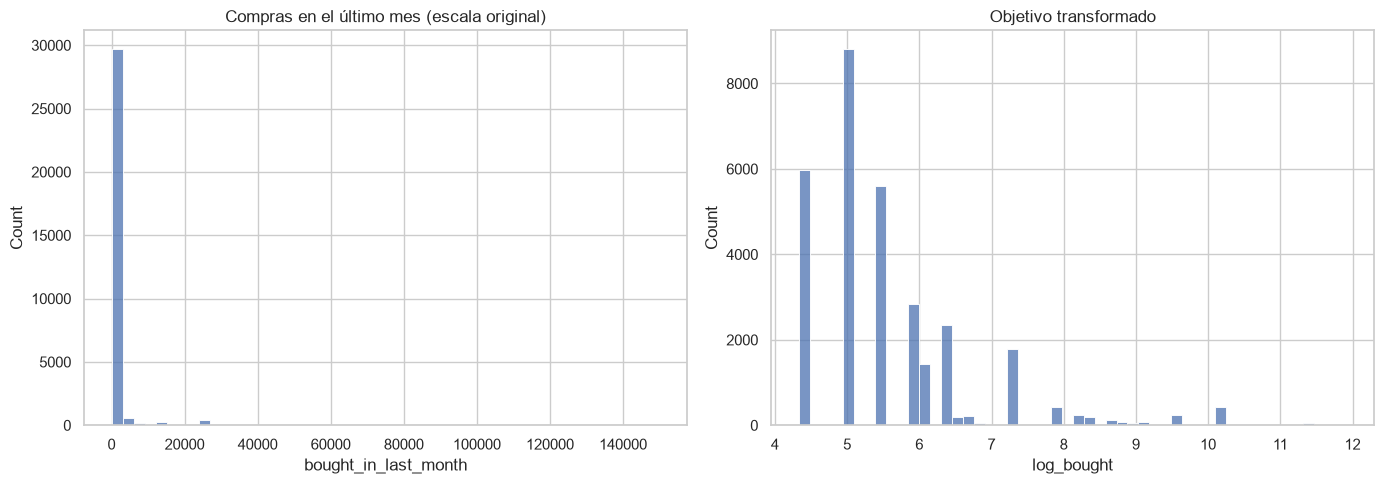

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df["bought_in_last_month"], bins=50, ax=axes[0])
axes[0].set_title("Compras en el último mes (escala original)")
axes[0].set_xlabel("bought_in_last_month")

sns.histplot(df["log_bought"], bins=50, ax=axes[1])
axes[1].set_title("Objetivo transformado")
axes[1].set_xlabel("log_bought")

plt.tight_layout()
plt.show()

## Selección de características y objetivo
El objetivo será `log_bought`. Se excluyen expresamente `bought_in_last_month` y `bought_cat`: la primera contiene el valor que se intenta predecir y la segunda se utiliza únicamente para estratificar.

Las variables `log_price`, `log_reviews` y `log_title_words` son transformaciones de predictores independientes del objetivo, por lo que sí pueden utilizarse. Se prefieren estas representaciones para evitar introducir simultáneamente versiones originales y logarítmicas redundantes.

El dataset v4 no incluye `delivery_cost` ni `log_delivery_cost`.

In [16]:
TARGET = "log_bought"
STRATIFY_COLUMN = "bought_cat"

NUMERIC_FEATURES = [
    "Rating",
    "log_reviews",
    "log_price",
    "log_title_words",
    "has_discount",
    "is_best_seller_flag",
    "is_sponsored_flag",
    "has_coupon",
    "is_free_delivery",
    "is_price_outlier",
    "has_sustainability_badge",
]

CATEGORICAL_FEATURES = ["buy_box_status"]
FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES

X = df[FEATURES].copy()
y = df[TARGET].astype(float).copy()
stratify_labels = df[STRATIFY_COLUMN].astype(str).copy()

# Verificación explícita contra fuga de información.
FORBIDDEN_FEATURES = {"bought_in_last_month", "bought_cat", "log_bought"}
assert not (set(FEATURES) & FORBIDDEN_FEATURES), "Se detectó una variable prohibida en X."

print("Número de características:", len(FEATURES))
print("Características numéricas:", NUMERIC_FEATURES)
print("Características categóricas:", CATEGORICAL_FEATURES)
print("Objetivo:", TARGET)

Número de características: 12
Características numéricas: ['Rating', 'log_reviews', 'log_price', 'log_title_words', 'has_discount', 'is_best_seller_flag', 'is_sponsored_flag', 'has_coupon', 'is_free_delivery', 'is_price_outlier', 'has_sustainability_badge']
Características categóricas: ['buy_box_status']
Objetivo: log_bought


## Preprocesamiento
Para las variables numéricas se utilizará imputación por mediana como protección adicional ante posibles valores faltantes. Para `buy_box_status` se imputará la categoría más frecuente y se aplicará One-Hot Encoding.

No se utiliza `StandardScaler`: los árboles de decisión dividen el espacio mediante umbrales y no dependen de que las variables estén en escalas comparables.

In [ ]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, NUMERIC_FEATURES),
        ("cat", categorical_transformer, CATEGORICAL_FEATURES),
    ],
    remainder="drop",
    verbose_feature_names_out=False
)

print("Preprocesador definido correctamente.")

Preprocesador definido correctamente.


## División de los datos
Se utilizará una partición 

70 entrenamiento | 
15 validación |
15 prueba. 
 
La estratificación se realiza con `bought_cat`, que no entra al modelo.

Se conserva el índice original de cada fila para facilitar la trazabilidad.

In [19]:
# Primera división: 70% entrenamiento y 30% temporal.
X_train, X_temp, y_train, y_temp, strat_train, strat_temp = train_test_split(
    X, y, stratify_labels,
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=stratify_labels
)

# Segunda división: 15% validación y 15% prueba.
X_val, X_test, y_val, y_test, strat_val, strat_test = train_test_split(
    X_temp, y_temp, strat_temp,
    test_size=0.50,
    random_state=RANDOM_STATE,
    stratify=strat_temp
)

print(f"Entrenamiento: {len(X_train):,} ({len(X_train)/len(df):.1%})")
print(f"Validación:    {len(X_val):,} ({len(X_val)/len(df):.1%})")
print(f"Prueba:        {len(X_test):,} ({len(X_test)/len(df):.1%})")

print("\nDistribución de bought_cat por partición:")
split_distribution = pd.DataFrame({
    "train": strat_train.value_counts(normalize=True),
    "validation": strat_val.value_counts(normalize=True),
    "test": strat_test.value_counts(normalize=True)
}).fillna(0)
display(split_distribution)

# Guardar índices para reutilizarlos en los demás notebooks.
split_indices = {
    "train": X_train.index.astype(int).tolist(),
    "validation": X_val.index.astype(int).tolist(),
    "test": X_test.index.astype(int).tolist(),
}
with open(OUTPUT_DIR / "split_indices.json", "w", encoding="utf-8") as f:
    json.dump(split_indices, f)

Entrenamiento: 21,841 (70.0%)
Validación:    4,680 (15.0%)
Prueba:        4,681 (15.0%)

Distribución de bought_cat por partición:


,train,validation,test
bought_cat,,,
201-500,0.316606,0.316667,0.316599
101-200,0.282084,0.282051,0.281991
>500,0.210064,0.210043,0.210211
50-100,0.191246,0.191239,0.191198


## Construcción del modelo base
Se define un Random Forest inicial con 300 árboles. `n_jobs`=-1 permite aprovechar los núcleos disponibles. `random_state` fija la aleatoriedad del ensamble.

La profundidad se deja sin límite en el modelo base; posteriormente se estudiará su efecto durante la optimización.

In [28]:
base_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=300,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        max_features=1.0
    ))
])

print(base_model)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['Rating', 'log_reviews',
                                                   'log_price',
                                                   'log_title_words',
                                                   'has_discount',
                                                   'is_best_seller_flag',
                                                   'is_sponsored_flag',
                                                   'has_coupon',
                                                   'is_free_delivery',
                                                   'is_price_outlier',
                                                   'has_sustainability_badge']),
                 

## Entrenamiento del modelo base
El modelo base se ajusta únicamente con el conjunto de entrenamiento. La validación se utiliza para observar su rendimiento preliminar, mientras que el conjunto de prueba permanece reservado.

In [21]:
start_time = time.perf_counter()
base_model.fit(X_train, y_train)
base_training_time = time.perf_counter() - start_time

base_val_pred = base_model.predict(X_val)

print(f"Tiempo de entrenamiento: {base_training_time:.2f} segundos")
print(f"MAE de validación: {mean_absolute_error(y_val, base_val_pred):.4f}")
print(f"RMSE de validación: {np.sqrt(mean_squared_error(y_val, base_val_pred)):.4f}")
print(f"R² de validación: {r2_score(y_val, base_val_pred):.4f}")

Tiempo de entrenamiento: 15.99 segundos
MAE de validación: 0.1919
RMSE de validación: 0.4995
R² de validación: 0.8253


## Optimización de hiperparámetros
Se comparará un conjunto acotado de configuraciones sobre entrenamiento y validación. La selección se hará mediante RMSE en escala logarítmica. No se consulta el conjunto de prueba durante esta etapa.

La búsqueda se mantiene deliberadamente moderada para que pueda ejecutarse en Colab sin consumir recursos excesivos. Si el tiempo lo permite, posteriormente se puede ampliar.

In [22]:
from sklearn.base import clone

param_distributions = {
    "model__n_estimators": [150, 250, 350],
    "model__max_depth": [10, 20, None],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": ["sqrt", 0.7, 1.0],
}

sampled_params = list(ParameterSampler(
    param_distributions,
    n_iter=12,
    random_state=RANDOM_STATE
))

search_results = []
best_rmse = np.inf
best_params = None
best_candidate = None

for candidate_number, params in enumerate(sampled_params, start=1):
    candidate = clone(base_model).set_params(**params)

    start = time.perf_counter()
    candidate.fit(X_train, y_train)
    fit_seconds = time.perf_counter() - start

    val_prediction = candidate.predict(X_val)
    val_rmse = np.sqrt(mean_squared_error(y_val, val_prediction))
    val_mae = mean_absolute_error(y_val, val_prediction)
    val_r2 = r2_score(y_val, val_prediction)

    row = {
        "candidate": candidate_number,
        "validation_RMSE_log": val_rmse,
        "validation_MAE_log": val_mae,
        "validation_R2_log": val_r2,
        "fit_seconds": fit_seconds,
        **params
    }
    search_results.append(row)

    print(
        f"[{candidate_number:02d}/{len(sampled_params)}] "
        f"RMSE={val_rmse:.4f} | MAE={val_mae:.4f} | "
        f"R²={val_r2:.4f} | {fit_seconds:.1f}s"
    )

    if val_rmse < best_rmse:
        best_rmse = val_rmse
        best_params = params
        best_candidate = candidate

search_results_df = pd.DataFrame(search_results).sort_values("validation_RMSE_log")
display(search_results_df)

print("Mejores parámetros:", best_params)
print(f"Mejor RMSE de validación: {best_rmse:.4f}")

search_results_df.to_csv(OUTPUT_DIR / "hyperparameter_search.csv", index=False)

[01/12] RMSE=0.4876 | MAE=0.1938 | R²=0.8335 | 11.8s
[02/12] RMSE=0.5020 | MAE=0.2029 | R²=0.8235 | 4.8s
[03/12] RMSE=0.5521 | MAE=0.3009 | R²=0.7865 | 3.4s
[04/12] RMSE=0.5634 | MAE=0.2998 | R²=0.7777 | 2.5s
[05/12] RMSE=0.4887 | MAE=0.1938 | R²=0.8327 | 4.8s
[06/12] RMSE=0.5624 | MAE=0.2995 | R²=0.7785 | 7.0s
[07/12] RMSE=0.4875 | MAE=0.1965 | R²=0.8336 | 8.2s
[08/12] RMSE=0.5638 | MAE=0.3006 | R²=0.7774 | 3.5s
[09/12] RMSE=0.5029 | MAE=0.2056 | R²=0.8229 | 4.8s
[10/12] RMSE=0.5011 | MAE=0.2014 | R²=0.8241 | 2.7s
[11/12] RMSE=0.4991 | MAE=0.1954 | R²=0.8256 | 4.5s
[12/12] RMSE=0.5083 | MAE=0.2473 | R²=0.8191 | 1.0s


,candidate,validation_RMSE_log,validation_MAE_log,validation_R2_log,fit_seconds,model__n_estimators,model__min_samples_split,model__min_samples_leaf,model__max_features,model__max_depth
6,7,0.487501,0.196489,0.833563,8.201769,350,5,2,0.7,20.0
0,1,0.487633,0.193791,0.833472,11.751996,350,2,1,0.7,20.0
4,5,0.488737,0.193837,0.832717,4.793062,250,2,1,0.7,20.0
10,11,0.499080,0.195422,0.825562,4.518697,250,10,1,1.0,NaN
9,10,0.501128,0.201365,0.824128,2.670396,150,2,4,1.0,NaN
1,2,0.502040,0.202854,0.823487,4.839486,150,10,2,1.0,20.0
8,9,0.502920,0.205574,0.822867,4.771977,250,2,4,1.0,20.0
11,12,0.508266,0.247309,0.819082,1.000996,150,2,4,sqrt,NaN
2,3,0.552141,0.300884,0.786499,3.436259,250,2,2,0.7,10.0
5,6,0.562426,0.299466,0.778471,6.964477,350,10,2,1.0,10.0


Mejores parámetros: {'model__n_estimators': 350, 'model__min_samples_split': 5, 'model__min_samples_leaf': 2, 'model__max_features': 0.7, 'model__max_depth': 20}
Mejor RMSE de validación: 0.4875


## Reentrenamiento y evaluación final
Una vez elegidos los hiperparámetros, se reentrena el modelo con entrenamiento + validación. El conjunto de prueba se utiliza una única vez para obtener la evaluación final.

Se reportan MAE, RMSE y R² en la escala logarítmica, y MAE, RMSE, R² y RMSLE en la escala original. Para volver a unidades de compras se aplica expm1 y se recortan predicciones negativas a cero.

In [23]:
X_trainval = pd.concat([X_train, X_val], axis=0)
y_trainval = pd.concat([y_train, y_val], axis=0)

final_model = clone(base_model).set_params(**best_params)

final_fit_start = time.perf_counter()
final_model.fit(X_trainval, y_trainval)
final_training_time = time.perf_counter() - final_fit_start

test_prediction_log = final_model.predict(X_test)

# Métricas en escala logarítmica.
mae_log = mean_absolute_error(y_test, test_prediction_log)
rmse_log = np.sqrt(mean_squared_error(y_test, test_prediction_log))
r2_log = r2_score(y_test, test_prediction_log)
# Métricas en escala original.
y_test_original = np.expm1(y_test)
test_prediction_original = np.maximum(0, np.expm1(test_prediction_log))

mae_original = mean_absolute_error(y_test_original, test_prediction_original)
rmse_original = np.sqrt(mean_squared_error(y_test_original, test_prediction_original))
r2_original = r2_score(y_test_original, test_prediction_original)
rmsle_original = np.sqrt(mean_squared_log_error(
    np.maximum(0, y_test_original),
    np.maximum(0, test_prediction_original)
))

metrics = {
    "model": "RandomForestRegressor",
    "MAE_log": mae_log,
    "RMSE_log": rmse_log,
    "R2_log": r2_log,
    "MAE_original": mae_original,
    "RMSE_original": rmse_original,
    "R2_original": r2_original,
    "RMSLE_original": rmsle_original,
    "training_seconds_final": final_training_time,
    "training_seconds_base": base_training_time,
    "best_params": best_params,
}

metrics_display = pd.DataFrame([
    {"Metric": "MAE (log)", "Value": mae_log},
    {"Metric": "RMSE (log)", "Value": rmse_log},
    {"Metric": "R² (log)", "Value": r2_log},
    {"Metric": "MAE (compras)", "Value": mae_original},
    {"Metric": "RMSE (compras)", "Value": rmse_original},
    {"Metric": "R² (compras)", "Value": r2_original},
    {"Metric": "RMSLE (compras)", "Value": rmsle_original},
    {"Metric": "Tiempo de entrenamiento final (s)", "Value": final_training_time},
])

display(metrics_display)

,Metric,Value
0,MAE (log),0.177153
1,RMSE (log),0.446328
2,R² (log),0.859634
3,MAE (compras),280.231853
4,RMSE (compras),1925.068412
5,R² (compras),0.865139
6,RMSLE (compras),0.446328
7,Tiempo de entrenamiento final (s),8.818966


## Visualización de resultados
Se comparan valores reales y predichos, y se inspecciona la distribución de residuos. Las gráficas se realizan en escala logarítmica para que la cola de ventas no oculte el comportamiento del modelo.

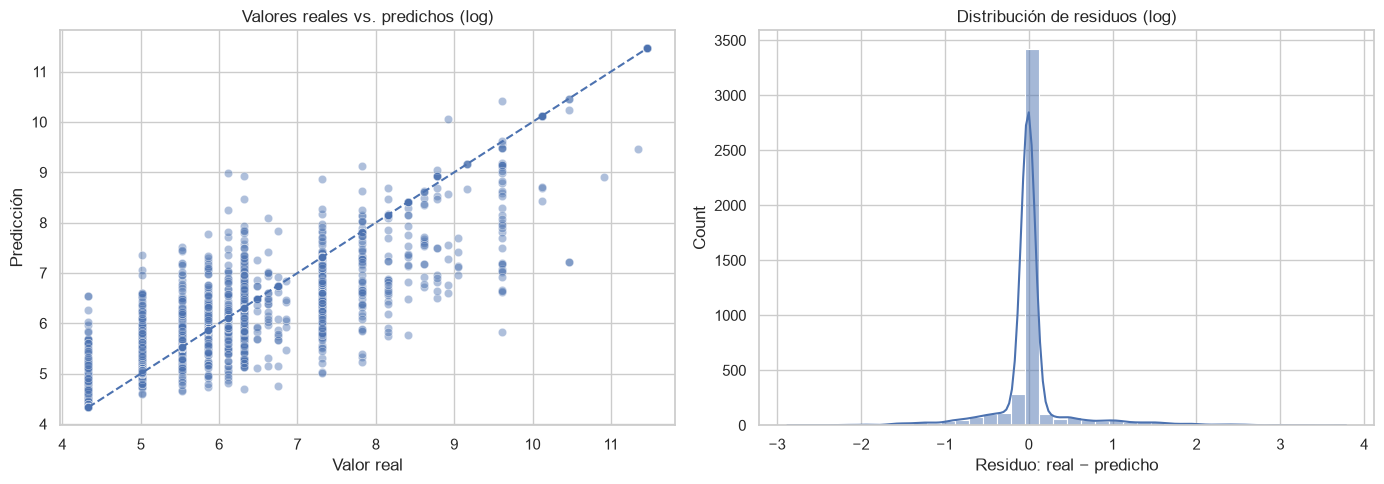

In [36]:
results_test = pd.DataFrame({
    "actual_log": y_test,
    "predicted_log": test_prediction_log,
    "actual_purchases": y_test_original,
    "predicted_purchases": test_prediction_original,
})
results_test["residual_log"] = results_test["actual_log"] - results_test["predicted_log"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(
    data=results_test, x="actual_log", y="predicted_log",
    alpha=0.45, ax=axes[0]
)
min_value = min(results_test["actual_log"].min(), results_test["predicted_log"].min())
max_value = max(results_test["actual_log"].max(), results_test["predicted_log"].max())
axes[0].plot([min_value, max_value], [min_value, max_value], linestyle="--")
axes[0].set_title("Valores reales vs. predichos (log)")
axes[0].set_xlabel("Valor real")
axes[0].set_ylabel("Predicción")

sns.histplot(results_test["residual_log"], bins=40, kde=True, ax=axes[1])
axes[1].set_title("Distribución de residuos (log)")
axes[1].set_xlabel("Residuo: real − predicho")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "residuals_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

In [30]:
error_analysis = pd.DataFrame({
    "bought_cat": strat_test,
    "actual": y_test_original,
    "predicted": test_prediction_original,
})
error_analysis["absolute_error"] = (
    error_analysis["actual"] - error_analysis["predicted"]
).abs()

display(
    error_analysis.groupby("bought_cat", observed=False)
    .agg(
        records=("absolute_error", "size"),
        MAE=("absolute_error", "mean"),
        median_absolute_error=("absolute_error", "median")
    )
    .sort_index()
)

,records,MAE,median_absolute_error
bought_cat,,,
101-200,1320,21.831051,1.278742
201-500,1482,60.643157,0.750995
50-100,895,11.412155,0.195838
>500,984,1202.094798,97.189512


## Importancia de características

,feature,importance
1,log_reviews,0.375428
2,log_price,0.257665
6,is_sponsored_flag,0.127492
0,Rating,0.083105
3,log_title_words,0.082069
5,is_best_seller_flag,0.017913
9,is_price_outlier,0.012524
10,has_sustainability_badge,0.011524
8,is_free_delivery,0.008178
4,has_discount,0.008053


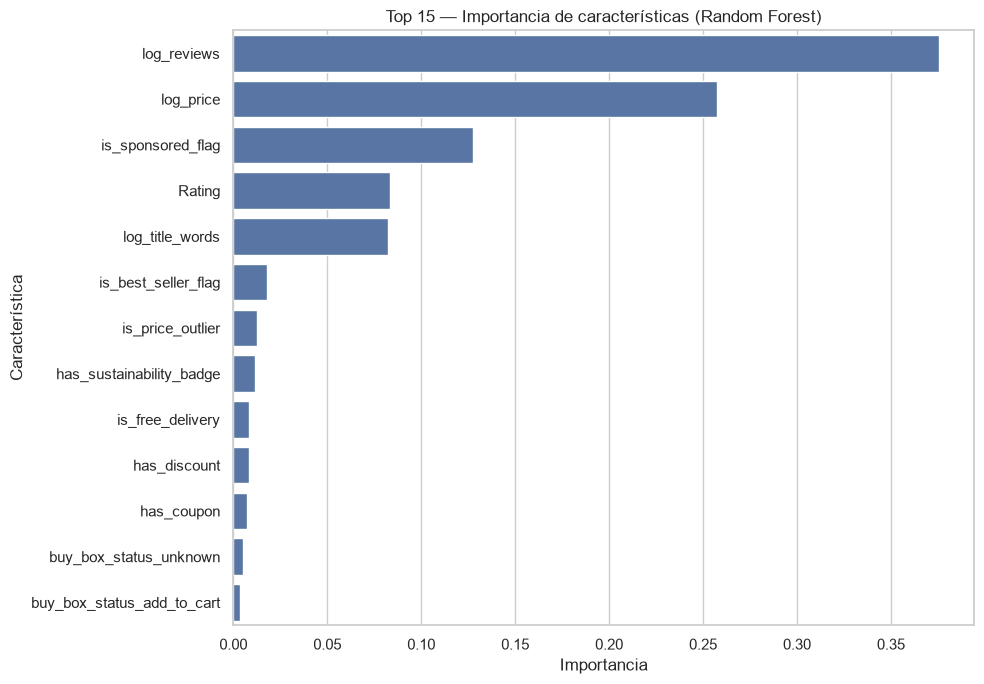

In [35]:
fitted_preprocessor = final_model.named_steps["preprocessor"]
fitted_rf = final_model.named_steps["model"]

try:
    transformed_feature_names = fitted_preprocessor.get_feature_names_out()
except Exception:
    transformed_feature_names = np.array(
        NUMERIC_FEATURES + ["buy_box_status_" + str(v) for v in
                            fitted_preprocessor.named_transformers_["cat"]
                            .named_steps["onehot"].get_feature_names_out(CATEGORICAL_FEATURES)]
    )

feature_importance = pd.DataFrame({
    "feature": transformed_feature_names,
    "importance": fitted_rf.feature_importances_
}).sort_values("importance", ascending=False)

display(feature_importance)

plt.figure(figsize=(10, 7))
sns.barplot(
    data=feature_importance.head(15),
    x="importance",
    y="feature"
)
plt.title("Top 15 — Importancia de características (Random Forest)")
plt.xlabel("Importancia")
plt.ylabel("Característica")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "Top_15_Feature_Importance.png", dpi=300, bbox_inches="tight")
plt.show()

## Arbol generado

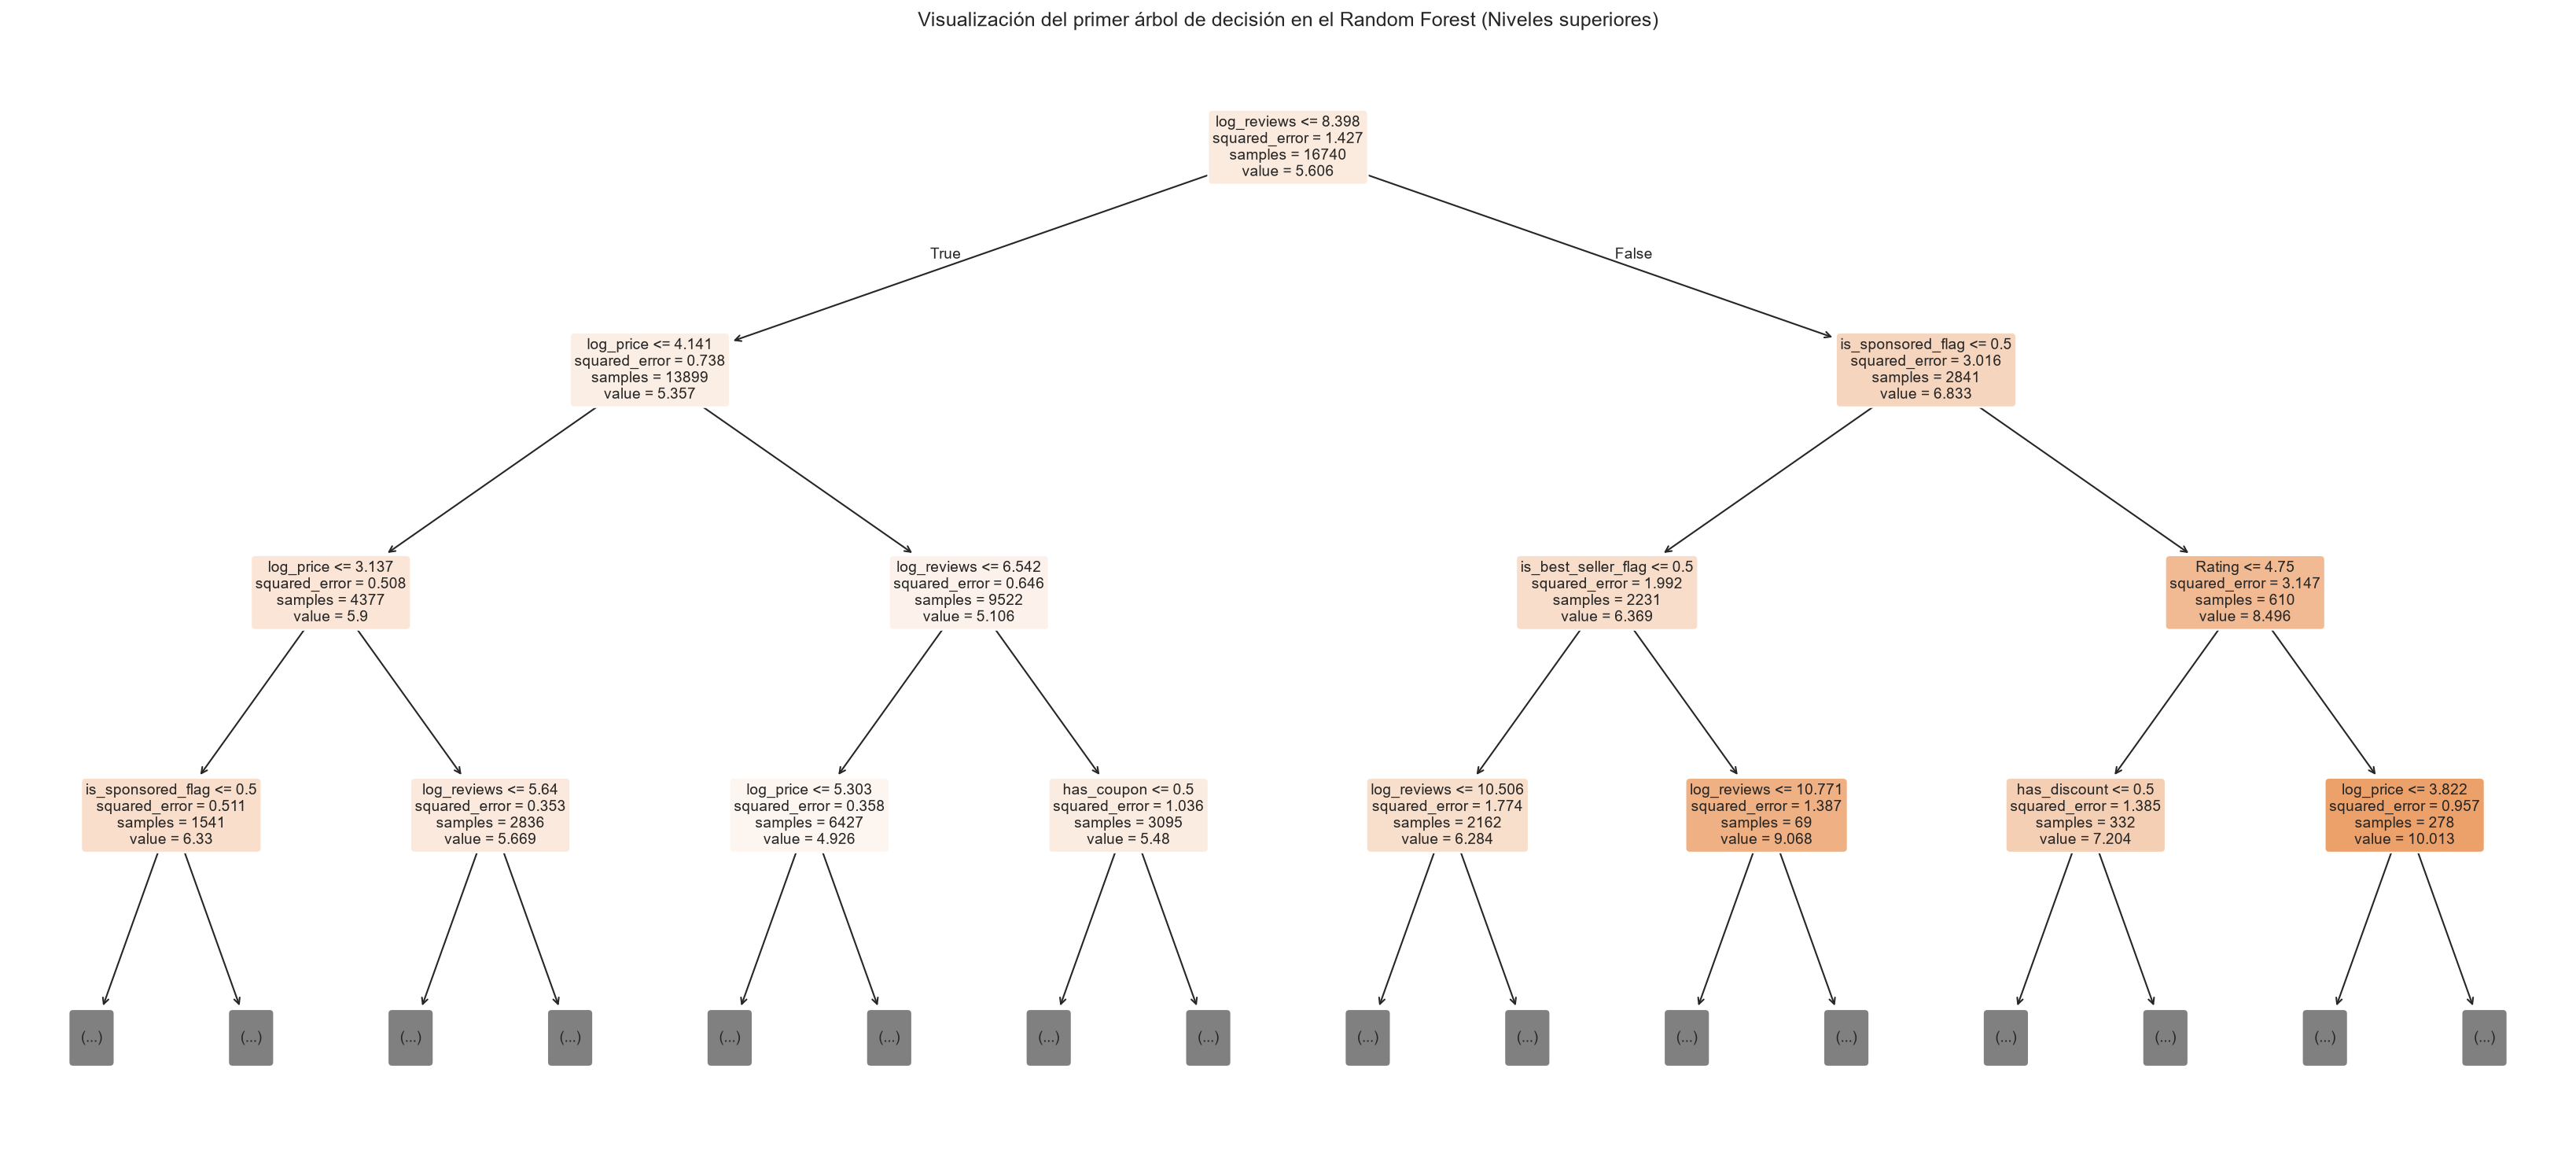

In [34]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

# 1. Extraer el modelo Random Forest del Pipeline final
# (Nota: Si quitaste el Pipeline en el paso anterior, usa rf_model = final_model)
rf_model = final_model.named_steps["model"]

# 2. Seleccionar un árbol individual del ensamble (por ejemplo, el primero en el índice 0)
primer_arbol = rf_model.estimators_[0]

# 3. Configurar la figura
plt.figure(figsize=(22, 10), dpi=150)

# 4. Generar el gráfico
plot_tree(
    primer_arbol,
    feature_names=transformed_feature_names, # Nombres extraídos en la celda 15
    max_depth=3,                             # Límite para evitar un gráfico ilegible
    filled=True,                             # Colorear nodos según la impureza/valor
    rounded=True,                            # Bordes redondeados en las cajas
    fontsize=9,
    precision=3
)

plt.title("Visualización del primer árbol de decisión en el Random Forest (Niveles superiores)")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "arbol_decision.png", dpi=300, bbox_inches="tight")
plt.show()

ExportTree = plot_tree

## Exportación de resultados

In [ ]:
# Predicciones con identificadores de índice para trazabilidad.
results_test.to_csv(OUTPUT_DIR / "test_predictions.csv", index=True)
feature_importance.to_csv(OUTPUT_DIR / "feature_importance.csv", index=False)
search_results_df.to_csv(OUTPUT_DIR / "hyperparameter_search.csv", index=False)

with open(OUTPUT_DIR / "metrics.json", "w", encoding="utf-8") as f:
    json.dump(metrics, f, ensure_ascii=False, indent=4, default=str)

joblib.dump(final_model, OUTPUT_DIR / "random_forest_final.joblib")

print("Archivos exportados en:", OUTPUT_DIR.resolve())
for file in sorted(OUTPUT_DIR.iterdir()):
    print("-", file.name)

Archivos exportados en: C:\Users\Juan Mona\Documents\Repositories\ProductScope-ML\Modelos entrenados\Models_Results\results_random_forest
- feature_importance.csv
- hyperparameter_search.csv
- metrics.json
- random_forest_final.joblib
- split_indices.json
- test_predictions.csv
